# Next-day purchase prediction

A fixed-midnight ranking experiment with chronological evaluation. Training code is reproducible in `src/`; this notebook inspects evidence, rather than requiring hidden training state. Dataset: Retailrocket, CC BY-NC-SA 4.0.

In [1]:
from pathlib import Path
import sys
import json
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
assert (ROOT / 'reports/data_quality.json').exists(), 'Run python -m src.pipeline all first'
REPORTS = ROOT / 'reports'


## 1. Prediction contract and leakage

Active visitors in `(t-24h,t]`; purchase label in `(t,t+24h]`. A transaction at exactly t is past history. Category joins are backward in time. Purge target horizons at chronological split boundaries. Daily observations predict returning purchases, not purchases completed earlier the same day.

In [2]:
feature_audit = json.loads((REPORTS / 'feature_audit.json').read_text())
display(pd.DataFrame(feature_audit['splits']).T)
print('Features:', ', '.join(feature_audit['features']))
print('Point-in-time checks:', feature_audit['validation'])


,rows,positives,positive_rate,observation_start,observation_end,label_end_max
purged,25349,35,0.001381,2015-07-24 00:00:00+00:00,2015-08-20 00:00:00+00:00,2015-08-21 00:00:00+00:00
test,313534,430,0.001371,2015-08-21 00:00:00+00:00,2015-09-17 00:00:00+00:00,2015-09-18 00:00:00+00:00
train,978396,1359,0.001389,2015-05-05 00:00:00+00:00,2015-07-23 00:00:00+00:00,2015-07-24 00:00:00+00:00
validation,317104,405,0.001277,2015-07-25 00:00:00+00:00,2015-08-19 00:00:00+00:00,2015-08-20 00:00:00+00:00


Features: views_1h, views_24h, unique_items_viewed_24h, repeat_views_24h, cart_additions_24h, last_session_duration_minutes, category_diversity_24h, unknown_category_views_24h, previous_transactions, hours_since_last_event
Point-in-time checks: {'point_in_time_checks_passed': True, 'train_validation_visitor_overlap': 19703, 'train_test_visitor_overlap': 14204}


## 2. Baselines and evaluation

Compare constant prevalence, weighted logistic regression, random forest and usable optional boosting. Select model by validation AP and threshold by validation F1. Test results do not change that decision. AP is the reported PR-AUC convention, and Precision@K uses a 1% capacity.

In [3]:
results = json.loads((REPORTS / 'model_results.json').read_text())
print('Selected using validation AP:', results['selected_model'])
print('Optional model status:', results['optional_models']['boosting'])
metrics = ['model', 'pr_auc_ap', 'roc_auc', 'precision', 'recall', 'f1', 'precision_at_1pct']
display(pd.read_csv(REPORTS / 'validation_metrics.csv')[metrics])
display(pd.read_csv(REPORTS / 'test_metrics.csv')[metrics])


Selected using validation AP: Logistic Regression
Optional model status: Skipped: no usable XGBoost/LightGBM runtime


,model,pr_auc_ap,roc_auc,precision,recall,f1,precision_at_1pct
0,Naive prevalence baseline,0.001277,0.500000,0.000000,0.00000,0.000000,0.000946
1,Logistic Regression,0.249223,0.900235,0.673913,0.22963,0.342541,0.061791
2,Random Forest,0.234901,0.873231,0.709924,0.22963,0.347015,0.053594


,model,pr_auc_ap,roc_auc,precision,recall,f1,precision_at_1pct
0,Naive prevalence baseline,0.001371,0.500000,0.000000,0.000000,0.000000,0.000638
1,Logistic Regression,0.239222,0.885775,0.635659,0.190698,0.293381,0.066645
2,Random Forest,0.240530,0.859361,0.640625,0.190698,0.293907,0.062500


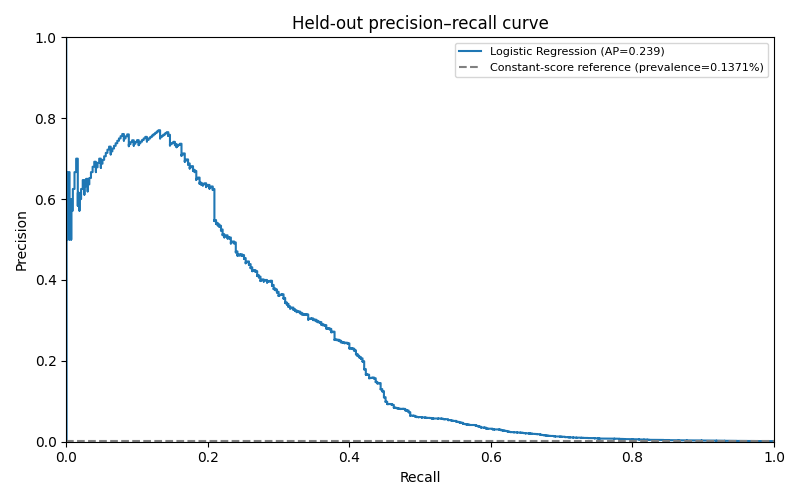

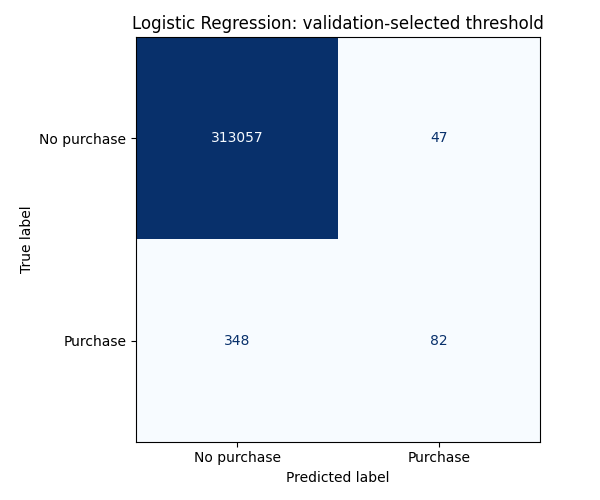

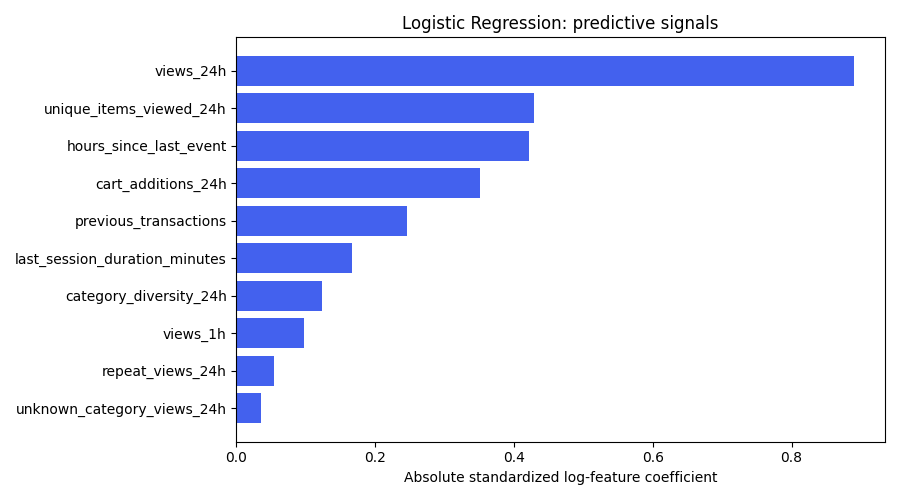

In [4]:
display(Image(filename=str(REPORTS / 'figures/precision_recall_curve.png')))
display(Image(filename=str(REPORTS / 'figures/confusion_matrix.png')))
display(Image(filename=str(REPORTS / 'figures/feature_importance.png')))


## 3. Error slices, calibration and uncertainty

Slices overlap and cannot be summed. Weighted-model scores are not calibrated purchase probabilities. A day-block AP interval estimates only approximate uncertainty.

In [5]:
display(pd.read_csv(REPORTS / 'error_slices.csv'))
display(pd.read_csv(REPORTS / 'calibration_bins.csv'))
errors = json.loads((REPORTS / 'error_analysis.json').read_text())
print('AP uncertainty:', errors['uncertainty'])
print('Daily top-1% pooled precision:', results['daily_capacity_precision_at_1pct'])


,slice,rows,positives,true_positives,false_positives,false_negatives,true_negatives,precision,recall,pr_auc_ap,roc_auc
0,all,313534,430,82,47,348,313057,0.635659,0.190698,0.239222,0.885775
1,visitor_seen_in_train,19813,102,20,23,82,19688,0.465116,0.196078,0.290668,0.936214
2,visitor_not_seen_in_train,293721,328,62,24,266,293369,0.720930,0.189024,0.228653,0.867526
3,cart_in_prior_24h,7923,194,77,47,117,7682,0.620968,0.396907,0.424581,0.888078
4,no_cart_in_prior_24h,305611,236,5,0,231,305375,1.000000,0.021186,0.103558,0.807642
5,previous_purchase,4426,204,82,47,122,4175,0.635659,0.401961,0.476283,0.885369
6,no_previous_purchase,309108,226,0,0,226,308882,0.000000,0.000000,0.012783,0.796561
7,unknown_category_views,44415,109,66,27,43,44279,0.709677,0.605505,0.562133,0.992161
8,no_unknown_category_views,269119,321,16,20,305,268778,0.444444,0.049844,0.112045,0.843678


,bin,rows,mean_score,observed_rate
0,"(0.0904, 0.123]",31354,0.111244,0.000096
1,"(0.123, 0.13]",31353,0.126183,0.000255
2,"(0.13, 0.148]",31353,0.135388,0.000255
3,"(0.148, 0.181]",31354,0.167692,0.000191
4,"(0.181, 0.201]",31353,0.191013,0.000287
5,"(0.201, 0.228]",31353,0.213794,0.000319
6,"(0.228, 0.269]",31354,0.247058,0.000638
7,"(0.269, 0.348]",31353,0.300036,0.000542
8,"(0.348, 0.475]",31353,0.413618,0.001148
9,"(0.475, 1.0]",31354,0.686544,0.009983


AP uncertainty: {'method': '100 UTC-day block bootstrap replicates; seed 42', 'pr_auc_ap_95pct_interval': [0.19957666413447211, 0.28901719483837013], 'limitation': 'Approximate temporal uncertainty; repeated visitors across days remain correlated'}
Daily top-1% pooled precision: 0.0670053985392188


## 4. Saved model and scoring parity

The model bundle keeps preprocessing and threshold together. Test locally computed features against the same predictions without publishing visitor records.

In [6]:
import joblib
import numpy as np
from src.predict import score_features
from src.features import FEATURES

bundle = joblib.load(ROOT / 'data/processed/selected_model.joblib')
snapshots = pd.read_pickle(ROOT / 'data/processed/visitor_snapshots.pkl')
test_sample = snapshots.loc[snapshots.split.eq('test')].head(100)
scored = score_features(bundle, test_sample)
stored = pd.read_csv(ROOT / 'data/processed/test_predictions.csv').head(100)
np.testing.assert_allclose(scored.score, stored.score, rtol=1e-10, atol=1e-12)
assert np.array_equal(scored.prediction, stored.prediction)
print('Scoring parity passed on 100 held-out snapshots.')
print('Model version:', bundle['metadata']['model_version'])


Scoring parity passed on 100 held-out snapshots.
Model version: v1-8b6b09610042-efc7dccf


## 5. Next experiment

Compare hourly or event-triggered observations on a fresh forward holdout. Preserve the full 24h horizon purge and avoid repeated test tuning. For a product intervention, evaluate incremental transactions in a randomized holdout, not only offline propensity.

**Practice:** explain why a high ROC-AUC can coexist with low precision under rare outcomes, and why the best test AP should not determine model selection.